# HAM10000 - Federated Training (Centralized · Local-only · FedAvg · FedProx)

This notebook runs every training arm of the proposal on the **frozen FL partition** (`HAM10000_fl_partition_v1.csv`, SHA-256 `0ab49e23…`, built on the v2 lesion split `bda53d19…`). It does not change any split or client assignment.

**Kaggle setup (once):**

1. *Settings → Accelerator:* **GPU T4 x2**. *Settings → Internet:* **On** (downloads ImageNet weights).
2. *Add Input:* `kmader/skin-cancer-mnist-ham10000` (images) and a private dataset containing `HAM10000_fl_partition_v1.csv`. The image folders (`part_1`, `part_2`) do not matter: images are matched by `image_id`, and the split comes only from the partition file.
3. **Save Version → Save & Run All (Commit)** so it runs in the background. Expected time on T4 x2: roughly 1.5–2.5 h for everything (stages A–D). The real per-epoch time is printed after stage A.

**What runs:**

| Stage | Runs | Purpose |
|---|---|---|
| 0 | tiny smoke test | catches errors in ~2 min before the long runs |
| A | centralized × {ResNet18, EfficientNet-B0}, seed 42 | pre-specified backbone rule (Sec. V-D) |
| B | local-only × 4, FedAvg, FedProx × µ-grid, seed 42 | main arms; µ chosen on pooled val |
| C | all main arms, seeds 43, 44 | seed variation |
| D | FedAvg with the secondary backbone | robustness check (Sec. V-E) |
| — | results, figures, LaTeX tables, demo export | report + Gradio demo |

Each run is skipped if its `metrics.json` already exists and resumes from `last.pt` if it was interrupted, so re-running a cell is safe. Two runs execute in parallel, one per T4.

**Fixed for all arms** (proposal Table III): 224×224 input, flips + 90° rotations + mild brightness/contrast, cross-entropy with inverse-sqrt class weights from the pooled training split, SGD (Nesterov, momentum 0.9, weight decay 1e-4), lr 0.01 with cosine decay, batch 32, budget 20 epochs (FL: R = 20 rounds × E = 1 local epoch). Model selection: best pooled-validation Macro-F1. Test is predicted once per final model.

In [1]:
import glob
import json
import os
import queue
import shutil
import subprocess
import sys
import threading
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ---- Paths --------------------------------------------------------------
INPUT_ROOT = Path(os.getenv("HAM_INPUT_ROOT", "/kaggle/input"))
WORK = Path(os.getenv("HAM_WORK_DIR", "/kaggle/working"))
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)  # fl_train.py is written here by the next cell

def find_one(name):
    hits = sorted(glob.glob(str(INPUT_ROOT / "**" / name), recursive=True))
    assert hits, f"{name} not found under {INPUT_ROOT}. Add the dataset that contains it."
    return Path(hits[0])

PARTITION_PATH = find_one("HAM10000_fl_partition_v1.csv")
CACHE_PATH = WORK / "cache" / "ham10000_224_uint8.npy"
RUNS_DIR = WORK / "runs"
LOG_DIR = WORK / "logs"
RESULTS_DIR = WORK / "results"
DEMO_DIR = WORK / "demo_models"
for d in (CACHE_PATH.parent, RUNS_DIR, LOG_DIR, RESULTS_DIR, DEMO_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Experiment settings (frozen before any run) -------------------------
EPOCHS = 20                 # centralized epochs = R x E
LOCAL_EPOCHS = 1            # E
SEEDS = [42, 43, 44]        # 42 = primary; 43, 44 only in stage C
MU_GRID = [0.001, 0.01, 0.1]
BACKBONES = ["resnet18", "efficientnet_b0"]
BACKBONE_MARGIN = 0.02      # Sec. V-D: if |diff| < 0.02, choose ResNet18
RUN_EXTRA_SEEDS = True      # stage C
RUN_ROBUSTNESS = True       # stage D
N_BOOTSTRAP = 1000

# Local dry run only (HAM_DEBUG=1): tiny subset, random init, CPU-friendly.
DEBUG = os.getenv("HAM_DEBUG") == "1"
EXTRA_ARGS = ["--debug-n", "8", "--no-pretrained", "--batch-size", "8"] if DEBUG else []
if DEBUG:
    EPOCHS, SEEDS, MU_GRID, N_BOOTSTRAP = 2, [42, 43], [0.01, 0.1], 50

N_GPUS = torch.cuda.device_count()
SLOTS = max(N_GPUS, 1)
print(f"Partition: {PARTITION_PATH}")
print(f"GPUs: {N_GPUS} {[torch.cuda.get_device_name(i) for i in range(N_GPUS)]}")
print(f"torch {torch.__version__} | python {sys.version.split()[0]} | DEBUG={DEBUG}")

Partition: /kaggle/input/datasets/kietvgpham/ham10000-fl-partition-v1/HAM10000_fl_partition_v1.csv
GPUs: 2 ['Tesla T4', 'Tesla T4']
torch 2.11.0+cu130 | python 3.13.16 | DEBUG=False


## 1. Training script

One script trains one run. It is written to the working directory so the notebook needs no extra upload, and the same file goes into the repo (`training/fl_train.py`).

In [2]:
%%writefile fl_train.py
#!/usr/bin/env python
"""Train one arm of the HAM10000 federated-learning study.

Arms (all share backbone, 224x224 input, augmentation, loss, optimizer and budget):
  centralized  pooled training split of all 4 clients
  local        one client only (--client)
  fedavg       FedAvg, sample-weighted averaging, all clients every round
  fedprox      FedAvg + proximal term (--mu)

Budget rule (proposal, Sec. V-C): R rounds x E local epochs = centralized epochs,
so every arm makes the same number of passes over each training image.

Model selection uses the pooled validation set only. The test set is predicted
once, with the best checkpoint, at the end of the run.

Usage:
  python fl_train.py --build-cache --partition P --image-root R --cache C
  python fl_train.py --arm fedavg --partition P --cache C --out-dir runs
"""
import argparse
import hashlib
import json
import math
import os
import platform
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]
CLIENTS = ["vidir_molemax", "vidir_modern", "rosendahl", "vienna_dias"]
FL_COLUMNS = ["image_id", "lesion_id", "dx", "split", "client"]
FL_MANIFEST_SHA256 = "0ab49e23b128c7d9f2d309bee762ade1d6ab69f04a31ca94096f29484c9a033d"
IMG_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


# --------------------------------------------------------------------------- data
def fingerprint(df, cols):
    """Same definition as 02_federated_client_partition.ipynb."""
    csv = df[cols].sort_values("image_id").to_csv(index=False, lineterminator="\n")
    return hashlib.sha256(csv.encode("utf-8")).hexdigest()


def load_partition(path, check=True):
    part = pd.read_csv(path)
    assert list(part.columns) == FL_COLUMNS, part.columns.tolist()
    if check:
        sha = fingerprint(part, FL_COLUMNS)
        if sha != FL_MANIFEST_SHA256:
            sys.exit(f"FL partition fingerprint mismatch: {sha}. Do not train on this file.")
    return part.sort_values("image_id").reset_index(drop=True)


def _load_one(path):
    from PIL import Image
    with Image.open(path) as im:
        im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8).transpose(2, 0, 1).copy()


def build_cache(partition_path, image_root, cache_path):
    """Resize every image once to 224x224 (proposal: 'resized to 224 x 224')."""
    from multiprocessing import Pool

    part = load_partition(partition_path)
    paths = {}
    for p in Path(image_root).rglob("ISIC_*.jpg"):
        paths.setdefault(p.stem, p)  # the Kaggle copy has duplicate folders; any copy is fine
    missing = [i for i in part["image_id"] if i not in paths]
    assert not missing, f"{len(missing)} images not found under {image_root}, e.g. {missing[:3]}"

    files = [str(paths[i]) for i in part["image_id"]]
    X = np.lib.format.open_memmap(cache_path, mode="w+", dtype=np.uint8,
                                  shape=(len(files), 3, IMG_SIZE, IMG_SIZE))
    t0 = time.time()
    with Pool(os.cpu_count()) as pool:
        for i, arr in enumerate(pool.imap(_load_one, files, chunksize=32)):
            X[i] = arr
            if (i + 1) % 2000 == 0:
                print(f"  cached {i + 1:,}/{len(files):,} ({time.time() - t0:.0f}s)", flush=True)
    X.flush()
    Path(str(cache_path) + ".ids.txt").write_text("\n".join(part["image_id"]) + "\n")
    print(f"Cache written: {cache_path} {X.shape} in {time.time() - t0:.0f}s")


def load_cache(cache_path, part):
    ids = Path(str(cache_path) + ".ids.txt").read_text().split()
    assert ids == part["image_id"].tolist(), "Cache order does not match the partition; rebuild it."
    return np.load(cache_path, mmap_mode="r")


# --------------------------------------------------------------------------- model
def build_model(name, pretrained):
    import torchvision
    w = "IMAGENET1K_V1" if pretrained else None
    if name == "resnet18":
        m = torchvision.models.resnet18(weights=w)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    elif name == "efficientnet_b0":
        m = torchvision.models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASSES))
    else:
        raise ValueError(name)
    return m


class Normalizer:
    def __init__(self, device):
        self.mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)

    def __call__(self, x_uint8):
        x = x_uint8.float().div_(255)
        return ((x - self.mean) / self.std).contiguous(memory_format=torch.channels_last)


def gpu_augment(x_uint8, gen):
    """Dihedral group (flip + 90-degree rotations) and mild brightness/contrast.

    Dermoscopic lesions have no canonical orientation, so all 8 orientations are valid.
    Runs on the GPU so the data pipeline never waits on the 4 Kaggle CPUs.
    """
    x = x_uint8.float().div_(255)
    b = x.shape[0]
    dev = x.device
    flip = torch.rand(b, device=dev, generator=gen) < 0.5
    x = torch.where(flip.view(b, 1, 1, 1), x.flip(3), x)
    k = torch.randint(0, 4, (b,), device=dev, generator=gen)
    out = x.clone()
    for r in (1, 2, 3):
        m = k == r
        if m.any():
            out[m] = torch.rot90(x[m], r, dims=(2, 3))
    bright = (torch.rand(b, 1, 1, 1, device=dev, generator=gen) - 0.5) * 0.2
    contrast = 1 + (torch.rand(b, 1, 1, 1, device=dev, generator=gen) - 0.5) * 0.2
    mean = out.mean(dim=(1, 2, 3), keepdim=True)
    out = ((out - mean) * contrast + mean + bright).clamp_(0, 1)
    return out.mul_(255)  # back to [0, 255] float; Normalizer divides again


# --------------------------------------------------------------------------- metrics
def compute_metrics(y, prob):
    pred = prob.argmax(1)
    k = len(CLASSES)
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    support = cm.sum(1)
    predicted = cm.sum(0)
    recall = np.divide(tp, support, out=np.zeros(k), where=support > 0)
    precision = np.divide(tp, predicted, out=np.zeros(k), where=predicted > 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(k), where=(precision + recall) > 0)
    return {
        "macro_f1": float(f1.mean()),
        "balanced_accuracy": float(recall[support > 0].mean()),
        "accuracy": float(tp.sum() / cm.sum()),
        "per_class": {c: {"precision": float(precision[i]), "recall": float(recall[i]),
                          "f1": float(f1[i]), "support": int(support[i])}
                      for i, c in enumerate(CLASSES)},
        "confusion_matrix": cm.tolist(),
    }


# --------------------------------------------------------------------------- training
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def cosine_lr(base, step, total):
    return base * 0.5 * (1 + math.cos(math.pi * step / total))


def make_optimizer(model, lr, args):
    return torch.optim.SGD(model.parameters(), lr=lr, momentum=args.momentum,
                           weight_decay=args.weight_decay, nesterov=True)


def train_one_epoch(model, opt, scaler, X, y, idx, ctx, global_params=None, mu=0.0):
    """One pass over `idx` (a 1-D LongTensor of rows on the device)."""
    model.train()
    perm = idx[torch.randperm(len(idx), device=idx.device, generator=ctx["gen"])]
    bs = ctx["batch_size"]
    total, n = 0.0, 0
    for s in range(0, len(perm), bs):
        bidx = perm[s:s + bs]
        if len(bidx) < 2:  # BatchNorm needs >1 sample
            continue
        xb = ctx["norm"](gpu_augment(X[bidx], ctx["gen"]))
        yb = y[bidx]
        with torch.autocast(device_type=ctx["device_type"], dtype=ctx["amp_dtype"],
                            enabled=ctx["amp"]):
            logits = model(xb)
        loss = F.cross_entropy(logits.float(), yb, weight=ctx["class_weights"])
        if mu > 0:
            prox = sum(((p - g) ** 2).sum() for p, g in zip(model.parameters(), global_params))
            loss = loss + 0.5 * mu * prox
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total += loss.item() * len(bidx)
        n += len(bidx)
    return total / max(n, 1)


@torch.no_grad()
def predict(model, X, idx, ctx, bs=256):
    model.eval()
    out = []
    for s in range(0, len(idx), bs):
        xb = ctx["norm"](X[idx[s:s + bs]])
        with torch.autocast(device_type=ctx["device_type"], dtype=ctx["amp_dtype"],
                            enabled=ctx["amp"]):
            out.append(model(xb).float().softmax(1))
    return torch.cat(out).cpu().numpy()


def fedavg_aggregate(states, weights):
    agg = {}
    for key, ref in states[0].items():
        if ref.is_floating_point():
            agg[key] = sum(w * s[key].float() for s, w in zip(states, weights)).to(ref.dtype)
        else:  # e.g. BatchNorm num_batches_tracked
            agg[key] = ref.clone()
    return agg


def clone_state(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items()}


def run_name_for(args):
    base = f"{args.arm}_{args.backbone}_s{args.seed}"
    if args.arm == "local":
        base = f"local-{args.client}_{args.backbone}_s{args.seed}"
    if args.arm == "fedprox":
        base = f"fedprox-mu{args.mu:g}_{args.backbone}_s{args.seed}"
    return args.run_name or base


def env_info(device):
    info = {"python": platform.python_version(), "torch": torch.__version__,
            "numpy": np.__version__, "pandas": pd.__version__}
    try:
        import torchvision
        info["torchvision"] = torchvision.__version__
    except ImportError:
        pass
    if device.type == "cuda":
        info["gpu"] = torch.cuda.get_device_name(device)
        info["cuda"] = torch.version.cuda
    return info


def main(args):
    if args.build_cache:
        build_cache(args.partition, args.image_root, args.cache)
        return

    run_dir = Path(args.out_dir) / run_name_for(args)
    if (run_dir / "metrics.json").exists():
        print(f"[skip] {run_dir.name} already finished")
        return
    run_dir.mkdir(parents=True, exist_ok=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.backends.cudnn.benchmark = True
    set_seed(args.seed)

    part = load_partition(args.partition)
    X_np = load_cache(args.cache, part)
    if args.debug_n:  # smoke test: a few images per client x split
        part = part.groupby(["client", "split"], group_keys=False).head(args.debug_n)
    rows = part.index.to_numpy()
    X = torch.from_numpy(np.ascontiguousarray(X_np[rows])).to(device)  # uint8 on the GPU (~1.5 GB)
    part = part.reset_index(drop=True)
    y = torch.tensor(part["dx"].map(CLASSES.index).to_numpy(), device=device)

    def rows_of(mask):
        return torch.tensor(np.flatnonzero(mask.to_numpy()), device=device)

    train_mask = part["split"] == "train"
    val_idx, test_idx = rows_of(part["split"] == "val"), rows_of(part["split"] == "test")
    client_idx = {c: rows_of(train_mask & (part["client"] == c)) for c in CLIENTS}
    pooled_idx = rows_of(train_mask)

    # Class weights: inverse square-root frequency of the pooled training split,
    # normalized to mean 1, identical for every arm.
    counts = np.bincount(part.loc[train_mask, "dx"].map(CLASSES.index), minlength=len(CLASSES))
    cw = 1.0 / np.sqrt(np.maximum(counts, 1))
    cw = cw / cw.mean()

    gen = torch.Generator(device=device)
    gen.manual_seed(args.seed)
    amp = device.type == "cuda"
    ctx = {"gen": gen, "batch_size": args.batch_size, "norm": Normalizer(device),
           "device_type": device.type, "amp": amp, "amp_dtype": torch.float16,
           "class_weights": torch.tensor(cw, dtype=torch.float32, device=device)}
    try:
        scaler = torch.amp.GradScaler(device.type, enabled=amp)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=amp)

    model = build_model(args.backbone, pretrained=not args.no_pretrained).to(device)
    model = model.to(memory_format=torch.channels_last)

    federated = args.arm in ("fedavg", "fedprox")
    if federated:
        assert args.epochs % args.local_epochs == 0, "epochs must be a multiple of local_epochs"
        n_steps = args.epochs // args.local_epochs  # rounds R
        mu = args.mu if args.arm == "fedprox" else 0.0
        sizes = np.array([len(client_idx[c]) for c in CLIENTS], dtype=float)
        agg_w = (sizes / sizes.sum()).tolist()
    else:
        n_steps = args.epochs
        train_idx = client_idx[args.client] if args.arm == "local" else pooled_idx
        opt = make_optimizer(model, args.lr, args)

    # ---- resume -------------------------------------------------------------
    start, best_f1, best_step, history = 0, -1.0, -1, []
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    if last_path.exists():
        ck = torch.load(last_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"])
        if not federated:
            opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        gen.set_state(ck["gen"])
        torch.set_rng_state(ck["torch_rng"])
        start, best_f1, best_step, history = ck["step"], ck["best_f1"], ck["best_step"], ck["history"]
        print(f"[resume] {run_dir.name} from step {start}")

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    t0 = time.time()
    y_val = y[val_idx].cpu().numpy()

    for step in range(start, n_steps):
        lr = cosine_lr(args.lr, step, n_steps)
        ts = time.time()
        if federated:
            global_state = clone_state(model)
            global_params = [p.detach().clone() for p in model.parameters()] if mu > 0 else None
            states, losses = [], []
            for c in CLIENTS:
                model.load_state_dict(global_state)
                copt = make_optimizer(model, lr, args)  # fresh client optimizer each round
                for _ in range(args.local_epochs):
                    losses.append(train_one_epoch(model, copt, scaler, X, y, client_idx[c], ctx,
                                                  global_params, mu))
                states.append(clone_state(model))
            model.load_state_dict(fedavg_aggregate(states, agg_w))
            del states
            train_loss = float(np.mean(losses))
        else:
            for g in opt.param_groups:
                g["lr"] = lr
            train_loss = train_one_epoch(model, opt, scaler, X, y, train_idx, ctx)

        val_prob = predict(model, X, val_idx, ctx)
        vm = compute_metrics(y_val, val_prob)
        improved = vm["macro_f1"] > best_f1
        if improved:
            best_f1, best_step = vm["macro_f1"], step + 1
            torch.save(model.state_dict(), best_path)
        history.append({"step": step + 1, "lr": lr, "train_loss": train_loss,
                        "val_macro_f1": vm["macro_f1"], "val_bal_acc": vm["balanced_accuracy"],
                        "val_acc": vm["accuracy"], "seconds": time.time() - ts})
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        print(f"{run_dir.name} {'round' if federated else 'epoch'} {step + 1}/{n_steps} "
              f"loss {train_loss:.4f} val-MF1 {vm['macro_f1']:.4f}{' *' if improved else ''} "
              f"({time.time() - ts:.0f}s)", flush=True)
        torch.save({"model": model.state_dict(), "opt": None if federated else opt.state_dict(),
                    "scaler": scaler.state_dict(), "gen": gen.get_state(),
                    "torch_rng": torch.get_rng_state(), "step": step + 1, "best_f1": best_f1,
                    "best_step": best_step, "history": history}, last_path)

    # ---- final evaluation with the best checkpoint (test used once) ----------
    model.load_state_dict(torch.load(best_path, map_location=device))
    val_prob = predict(model, X, val_idx, ctx)
    test_prob = predict(model, X, test_idx, ctx)
    y_test = y[test_idx].cpu().numpy()
    np.savez_compressed(
        run_dir / "preds.npz",
        val_ids=part.loc[val_idx.cpu().numpy(), "image_id"].to_numpy(), val_y=y_val, val_prob=val_prob,
        test_ids=part.loc[test_idx.cpu().numpy(), "image_id"].to_numpy(), test_y=y_test,
        test_prob=test_prob)

    metrics = {
        "run": run_dir.name, "arm": args.arm, "client": args.client if args.arm == "local" else None,
        "backbone": args.backbone, "seed": args.seed,
        "mu": args.mu if args.arm == "fedprox" else (0.0 if federated else None),
        "epochs_budget": args.epochs,
        "rounds": n_steps if federated else None,
        "local_epochs": args.local_epochs if federated else None,
        "lr": args.lr, "momentum": args.momentum, "weight_decay": args.weight_decay,
        "batch_size": args.batch_size, "optimizer": "SGD nesterov, cosine schedule",
        "loss": "cross-entropy, inverse-sqrt class weights (pooled train)",
        "class_weights": dict(zip(CLASSES, map(float, cw))),
        "n_train_images": int(sum(len(v) for v in client_idx.values())) if federated or args.arm == "centralized"
        else int(len(client_idx[args.client])),
        "best_step": best_step, "selection": "best pooled-val macro-F1",
        "val": compute_metrics(y_val, val_prob), "test": compute_metrics(y_test, test_prob),
        "train_seconds": time.time() - t0,
        "peak_gpu_mem_gb": (torch.cuda.max_memory_allocated(device) / 1e9) if device.type == "cuda" else None,
        "debug_n": args.debug_n, "env": env_info(device),
    }
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    last_path.unlink(missing_ok=True)
    print(f"[done] {run_dir.name}: best {('round' if federated else 'epoch')} {best_step}, "
          f"val MF1 {metrics['val']['macro_f1']:.4f}, test MF1 {metrics['test']['macro_f1']:.4f}, "
          f"{metrics['train_seconds'] / 60:.1f} min")


def parse_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--build-cache", action="store_true")
    p.add_argument("--image-root", default="/kaggle/input")
    p.add_argument("--partition", required=True)
    p.add_argument("--cache", required=True)
    p.add_argument("--out-dir", default="runs")
    p.add_argument("--run-name", default=None)
    p.add_argument("--arm", choices=["centralized", "local", "fedavg", "fedprox"], default="centralized")
    p.add_argument("--client", choices=CLIENTS, default=None)
    p.add_argument("--backbone", choices=["resnet18", "efficientnet_b0"], default="resnet18")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--epochs", type=int, default=20, help="budget: centralized epochs = R x E")
    p.add_argument("--local-epochs", type=int, default=1, help="E (federated arms)")
    p.add_argument("--mu", type=float, default=0.0, help="FedProx proximal weight")
    p.add_argument("--lr", type=float, default=0.01)
    p.add_argument("--momentum", type=float, default=0.9)
    p.add_argument("--weight-decay", type=float, default=1e-4)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--no-pretrained", action="store_true")
    p.add_argument("--debug-n", type=int, default=0, help="smoke test: images per client x split")
    a = p.parse_args(argv)
    if a.arm == "local" and a.client is None:
        p.error("--arm local needs --client")
    if a.arm == "fedprox" and a.mu <= 0:
        p.error("--arm fedprox needs --mu > 0")
    return a


if __name__ == "__main__":
    main(parse_args())

Writing fl_train.py


## 2. Verify the frozen partition

In [3]:
import importlib
import fl_train
importlib.reload(fl_train)
from fl_train import CLASSES, CLIENTS, FL_COLUMNS, FL_MANIFEST_SHA256, fingerprint

part = pd.read_csv(PARTITION_PATH)
sha = fingerprint(part, FL_COLUMNS)
assert sha == FL_MANIFEST_SHA256, f"Partition fingerprint mismatch: {sha}"
counts = part["split"].value_counts().to_dict()
assert counts == {"train": 6981, "val": 1532, "test": 1502}, counts
assert part.groupby("lesion_id")["split"].nunique().max() == 1, "lesion in >1 split"
print(f"FL partition verified: {sha[:8]}…  {counts}")
display(pd.crosstab(part["client"], part["split"]).reindex(CLIENTS)[["train", "val", "test"]])
display(pd.crosstab(part.loc[part.split == "train", "client"],
                    part.loc[part.split == "train", "dx"]).reindex(index=CLIENTS, columns=CLASSES))

FL partition verified: 0ab49e23…  {'train': 6981, 'val': 1532, 'test': 1502}


split,train,val,test
client,,,
vidir_molemax,2762,592,600
vidir_modern,2356,501,506
rosendahl,1553,376,330
vienna_dias,310,63,66


dx,nv,mel,bkl,bcc,akiec,vasc,df
client,,,,,,,
vidir_molemax,2602,13,82,0,0,38,27
vidir_modern,1308,449,340,151,24,57,27
rosendahl,537,250,343,208,198,2,15
vienna_dias,236,61,7,2,0,2,2


## 3. Image cache (resize once to 224×224) and ImageNet weights

In [4]:
if not CACHE_PATH.exists():
    subprocess.run([sys.executable, "fl_train.py", "--build-cache", "--partition", str(PARTITION_PATH),
                    "--image-root", str(INPUT_ROOT), "--cache", str(CACHE_PATH)], check=True)
else:
    print(f"Cache exists: {CACHE_PATH}")

if not DEBUG:  # download once so two parallel jobs never race on the same file
    import torchvision
    torchvision.models.resnet18(weights="IMAGENET1K_V1")
    torchvision.models.efficientnet_b0(weights="IMAGENET1K_V1")
    print("ImageNet weights cached")

  cached 2,000/10,015 (22s)
  cached 4,000/10,015 (43s)
  cached 6,000/10,015 (62s)
  cached 8,000/10,015 (82s)
  cached 10,000/10,015 (102s)
Cache written: /kaggle/working/cache/ham10000_224_uint8.npy (10015, 3, 224, 224) in 102s
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 146MB/s]

ImageNet weights cached


## 4. Job runner (one run per GPU, in parallel)

In [5]:
COMMON = ["--partition", str(PARTITION_PATH), "--cache", str(CACHE_PATH), "--out-dir", str(RUNS_DIR),
          "--epochs", str(EPOCHS), "--local-epochs", str(LOCAL_EPOCHS), *EXTRA_ARGS]

def run_name(job):
    return fl_train.run_name_for(fl_train.parse_args(COMMON + job))

def run_jobs(jobs, stage):
    q = queue.Queue()
    for j in jobs:
        q.put(j)
    failures, lock, t_stage = [], threading.Lock(), time.time()

    def worker(slot):
        while True:
            try:
                job = q.get_nowait()
            except queue.Empty:
                return
            name = run_name(job)
            env = dict(os.environ)
            if N_GPUS:
                env["CUDA_VISIBLE_DEVICES"] = str(slot)
            t0 = time.time()
            with open(LOG_DIR / f"{name}.log", "a") as log:
                rc = subprocess.run([sys.executable, "fl_train.py", *COMMON, *job],
                                    stdout=log, stderr=subprocess.STDOUT, env=env).returncode
            tail = (LOG_DIR / f"{name}.log").read_text().strip().splitlines()[-1:]
            with lock:
                print(f"[{stage}][gpu{slot}] {'OK  ' if rc == 0 else 'FAIL'} {name:42s} "
                      f"{(time.time() - t0) / 60:5.1f} min | {tail[0] if tail else ''}", flush=True)
                if rc:
                    failures.append(name)

    threads = [threading.Thread(target=worker, args=(s,)) for s in range(SLOTS)]
    for t in threads:
        t.start()
    for t in threads:
        t.join()
    print(f"[{stage}] finished in {(time.time() - t_stage) / 60:.1f} min")
    if failures:
        raise RuntimeError(f"Failed runs: {failures}. See {LOG_DIR}/<run>.log")

def metrics(name):
    return json.loads((RUNS_DIR / name / "metrics.json").read_text())

def val_f1(name):
    return metrics(name)["val"]["macro_f1"]

## 5. Stage 0 - smoke test

A 2-round FedProx and a local-only run on 16 images per client × split. If this fails, fix it before spending GPU time on stage A.

In [6]:
smoke_dir = WORK / "smoke"
shutil.rmtree(smoke_dir, ignore_errors=True)
for job in (["--arm", "fedprox", "--mu", "0.01"], ["--arm", "local", "--client", "vienna_dias"]):
    args = [*COMMON, *job, "--out-dir", str(smoke_dir), "--epochs", "2", "--debug-n", "16"]
    if DEBUG:
        args += ["--no-pretrained"]
    r = subprocess.run([sys.executable, "fl_train.py", *args], capture_output=True, text=True)
    print(r.stdout[-600:], r.stderr[-2000:])
    assert r.returncode == 0, "Smoke test failed - see the error above"
shutil.rmtree(smoke_dir, ignore_errors=True)
print("Smoke test passed")

fedprox-mu0.01_resnet18_s42 round 1/2 loss 2.0389 val-MF1 0.1480 * (7s)
fedprox-mu0.01_resnet18_s42 round 2/2 loss 1.5930 val-MF1 0.1433 (0s)
[done] fedprox-mu0.01_resnet18_s42: best round 1, val MF1 0.1480, test MF1 0.1295, 0.1 min
 
local-vienna_dias_resnet18_s42 epoch 1/2 loss 1.8784 val-MF1 0.1039 * (1s)
local-vienna_dias_resnet18_s42 epoch 2/2 loss 0.5222 val-MF1 0.0921 (0s)
[done] local-vienna_dias_resnet18_s42: best epoch 1, val MF1 0.1039, test MF1 0.1195, 0.0 min
 
Smoke test passed


## 6. Stage A - backbone selection (centralized only, validation only)

Rule fixed before any run (proposal Sec. V-D): the backbone with the higher pooled-validation Macro-F1 becomes primary; if the difference is below 0.02, ResNet18. No test data and no FL run is involved.

In [7]:
run_jobs([["--arm", "centralized", "--backbone", b, "--seed", "42"] for b in BACKBONES[::-1]], "A")

pilot = []
for b in BACKBONES:
    m = metrics(f"centralized_{b}_s42")
    pilot.append({"backbone": b, "val_macro_f1": m["val"]["macro_f1"], "best_epoch": m["best_step"],
                  "sec_per_epoch": m["train_seconds"] / EPOCHS, "peak_gpu_mem_gb": m["peak_gpu_mem_gb"]})
pilot = pd.DataFrame(pilot).set_index("backbone")
diff = pilot.loc["efficientnet_b0", "val_macro_f1"] - pilot.loc["resnet18", "val_macro_f1"]
PRIMARY = "efficientnet_b0" if diff >= BACKBONE_MARGIN else "resnet18"
SECONDARY = [b for b in BACKBONES if b != PRIMARY][0]
decision = {"rule": f"higher pooled-val macro-F1; ResNet18 if |diff| < {BACKBONE_MARGIN}",
            "val_macro_f1": pilot["val_macro_f1"].round(4).to_dict(), "diff_effnet_minus_resnet": round(diff, 4),
            "primary": PRIMARY, "secondary": SECONDARY}
(RESULTS_DIR / "backbone_decision.json").write_text(json.dumps(decision, indent=2))
pilot.to_csv(RESULTS_DIR / "backbone_pilot.csv")
display(pilot.round(4))
print(f"PRIMARY = {PRIMARY}   SECONDARY = {SECONDARY}")

[A][gpu1] OK   centralized_resnet18_s42                     3.2 min | [done] centralized_resnet18_s42: best epoch 20, val MF1 0.6003, test MF1 0.5683, 3.1 min
[A][gpu0] OK   centralized_efficientnet_b0_s42              6.7 min | [done] centralized_efficientnet_b0_s42: best epoch 20, val MF1 0.7583, test MF1 0.7288, 6.6 min
[A] finished in 6.7 min


,val_macro_f1,best_epoch,sec_per_epoch,peak_gpu_mem_gb
backbone,,,,
resnet18,0.6003,20,9.4289,3.3086
efficientnet_b0,0.7583,20,19.7854,5.6863


PRIMARY = efficientnet_b0   SECONDARY = resnet18


## 7. Stage B - main arms, seed 42 (+ FedProx µ selection on validation)

In [8]:
def main_jobs(seed, mus):
    s = ["--backbone", PRIMARY, "--seed", str(seed)]
    jobs = [["--arm", "fedavg", *s]] + [["--arm", "fedprox", "--mu", str(m), *s] for m in mus]
    jobs += [["--arm", "centralized", *s]]
    jobs += [["--arm", "local", "--client", c, *s] for c in CLIENTS]
    return jobs

run_jobs(main_jobs(42, MU_GRID), "B")

mu_table = pd.DataFrame([{"mu": m, "val_macro_f1": val_f1(f"fedprox-mu{m:g}_{PRIMARY}_s42"),
                          "best_round": metrics(f"fedprox-mu{m:g}_{PRIMARY}_s42")["best_step"]}
                         for m in sorted(MU_GRID)])
mu_table.loc[len(mu_table)] = {"mu": 0.0, "val_macro_f1": val_f1(f"fedavg_{PRIMARY}_s42"),
                               "best_round": metrics(f"fedavg_{PRIMARY}_s42")["best_step"]}
MU_BEST = float(mu_table.loc[mu_table["mu"] > 0].sort_values(["val_macro_f1", "mu"], ascending=[False, True])
                .iloc[0]["mu"])
mu_table.to_csv(RESULTS_DIR / "fedprox_mu_selection.csv", index=False)
display(mu_table.round(4))
print(f"Selected µ = {MU_BEST:g} (pooled validation only; µ = 0 is FedAvg, shown for reference)")

[B][gpu0] OK   fedavg_efficientnet_b0_s42                   7.3 min | [done] fedavg_efficientnet_b0_s42: best round 14, val MF1 0.6574, test MF1 0.6202, 7.2 min
[B][gpu1] OK   fedprox-mu0.001_efficientnet_b0_s42          9.3 min | [done] fedprox-mu0.001_efficientnet_b0_s42: best round 20, val MF1 0.6740, test MF1 0.6599, 9.2 min
[B][gpu0] OK   fedprox-mu0.01_efficientnet_b0_s42           9.3 min | [done] fedprox-mu0.01_efficientnet_b0_s42: best round 17, val MF1 0.6552, test MF1 0.6563, 9.2 min
[B][gpu0] OK   centralized_efficientnet_b0_s42              0.0 min | [skip] centralized_efficientnet_b0_s42 already finished
[B][gpu1] OK   fedprox-mu0.1_efficientnet_b0_s42            9.5 min | [done] fedprox-mu0.1_efficientnet_b0_s42: best round 20, val MF1 0.6626, test MF1 0.6418, 9.4 min
[B][gpu0] OK   local-vidir_molemax_efficientnet_b0_s42      3.4 min | [done] local-vidir_molemax_efficientnet_b0_s42: best epoch 8, val MF1 0.3274, test MF1 0.3007, 3.3 min
[B][gpu1] OK   local-vidir_modern

,mu,val_macro_f1,best_round
0,0.001,0.6740,20
1,0.010,0.6552,17
2,0.100,0.6626,20
3,0.000,0.6574,14


Selected µ = 0.001 (pooled validation only; µ = 0 is FedAvg, shown for reference)


## 8. Stage C - extra seeds · Stage D - robustness (secondary backbone)

In [9]:
if RUN_EXTRA_SEEDS:
    run_jobs([j for s in SEEDS[1:] for j in main_jobs(s, [MU_BEST])], "C")
if RUN_ROBUSTNESS:  # centralized with the secondary backbone already exists from stage A
    run_jobs([["--arm", "fedavg", "--backbone", SECONDARY, "--seed", "42"]], "D")

[C][gpu0] OK   fedavg_efficientnet_b0_s43                   7.3 min | [done] fedavg_efficientnet_b0_s43: best round 18, val MF1 0.6568, test MF1 0.6305, 7.2 min
[C][gpu1] OK   fedprox-mu0.001_efficientnet_b0_s43          9.5 min | [done] fedprox-mu0.001_efficientnet_b0_s43: best round 19, val MF1 0.6478, test MF1 0.6204, 9.4 min
[C][gpu1] OK   local-vidir_molemax_efficientnet_b0_s43      3.4 min | [done] local-vidir_molemax_efficientnet_b0_s43: best epoch 14, val MF1 0.3369, test MF1 0.3240, 3.3 min
[C][gpu0] OK   centralized_efficientnet_b0_s43              6.6 min | [done] centralized_efficientnet_b0_s43: best epoch 16, val MF1 0.7531, test MF1 0.7043, 6.5 min
[C][gpu1] OK   local-vidir_modern_efficientnet_b0_s43       3.1 min | [done] local-vidir_modern_efficientnet_b0_s43: best epoch 14, val MF1 0.6097, test MF1 0.5770, 3.0 min
[C][gpu0] OK   local-rosendahl_efficientnet_b0_s43          2.5 min | [done] local-rosendahl_efficientnet_b0_s43: best epoch 13, val MF1 0.4494, test MF1 0.

## 9. Results

Primary metric: pooled-test Macro-F1. Local-only is reported as the mean over the 4 client models (each evaluated on the same pooled test set). Uncertainty: (i) mean ± SD over seeds; (ii) 95% bootstrap CI that resamples **test lesions** (all images of a lesion stay together), with seeds averaged inside each bootstrap sample. Gaps vs centralized are paired on the same resamples.

In [10]:
rows = []
for f in sorted(RUNS_DIR.glob("*/metrics.json")):
    m = json.loads(f.read_text())
    r = {k: m[k] for k in ("run", "arm", "client", "backbone", "seed", "mu", "best_step")}
    r.update({"val_macro_f1": m["val"]["macro_f1"], "test_macro_f1": m["test"]["macro_f1"],
              "test_bal_acc": m["test"]["balanced_accuracy"], "test_acc": m["test"]["accuracy"],
              "minutes": m["train_seconds"] / 60, "peak_gpu_mem_gb": m["peak_gpu_mem_gb"]})
    r.update({f"recall_{c}": m["test"]["per_class"][c]["recall"] for c in CLASSES})
    rows.append(r)
runs = pd.DataFrame(rows)
runs.to_csv(RESULTS_DIR / "all_runs.csv", index=False)

ARMS = ["Centralized", "Local-only", "FedAvg", f"FedProx (µ={MU_BEST:g})"]

def arm_runs(arm, backbone=None, seeds=None):
    backbone = backbone or PRIMARY
    df = runs[(runs.backbone == backbone) & runs.seed.isin(seeds or SEEDS)]
    if arm == "Centralized":
        return df[df.arm == "centralized"]
    if arm == "Local-only":
        return df[df.arm == "local"]
    if arm == "FedAvg":
        return df[df.arm == "fedavg"]
    return df[(df.arm == "fedprox") & np.isclose(df.mu.astype(float), MU_BEST)]

def per_seed(df, col):  # local-only: average the 4 client models within a seed first
    return df.groupby("seed")[col].mean()

summary = []
for a in ARMS:
    df = arm_runs(a)
    row = {"arm": a, "n_seeds": df.seed.nunique()}
    for col in ("test_macro_f1", "test_bal_acc", "test_acc"):
        s = per_seed(df, col)
        row[col] = s.mean()
        row[col + "_sd"] = s.std(ddof=1) if len(s) > 1 else np.nan
    summary.append(row)
summary = pd.DataFrame(summary).set_index("arm")

# ---- lesion-level bootstrap ------------------------------------------------
ref_ids = np.load(RUNS_DIR / f"centralized_{PRIMARY}_s42" / "preds.npz", allow_pickle=True)["test_ids"]
test_part = part.set_index("image_id").loc[ref_ids].reset_index()
assert DEBUG or len(test_part) == 1502
lesion_codes, _ = pd.factorize(test_part["lesion_id"])
groups = [np.flatnonzero(lesion_codes == g) for g in range(lesion_codes.max() + 1)]
rng = np.random.default_rng(2026)
boot_idx = [np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])
            for _ in range(N_BOOTSTRAP)]

def macro_f1(y, p, k=len(CLASSES)):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm)
    denom = cm.sum(0) + cm.sum(1)
    return np.mean(np.divide(2 * tp, denom, out=np.zeros(k), where=denom > 0))

def load_test_pred(name):
    z = np.load(RUNS_DIR / name / "preds.npz", allow_pickle=True)
    assert (z["test_ids"] == test_part["image_id"].to_numpy()).all()
    return z["test_y"], z["test_prob"].argmax(1)

def boot_scores(df):
    # per bootstrap sample: mean over all runs of the arm (seeds, and clients for local-only)
    preds = [load_test_pred(n) for n in df.run]
    return np.array([np.mean([macro_f1(y[ix], p[ix]) for y, p in preds]) for ix in boot_idx])

boot = {a: boot_scores(arm_runs(a)) for a in ARMS}
for a in ARMS:
    summary.loc[a, "ci_low"], summary.loc[a, "ci_high"] = np.percentile(boot[a], [2.5, 97.5])
    gap = boot[a] - boot["Centralized"]
    summary.loc[a, "gap_vs_central"] = summary.loc[a, "test_macro_f1"] - summary.loc["Centralized", "test_macro_f1"]
    summary.loc[a, "gap_ci_low"], summary.loc[a, "gap_ci_high"] = np.percentile(gap, [2.5, 97.5])
summary.to_csv(RESULTS_DIR / "main_results.csv")
print(f"Backbone: {PRIMARY} | seeds: {SEEDS} | budget: {EPOCHS} epochs (FL: R={EPOCHS // LOCAL_EPOCHS}, E={LOCAL_EPOCHS})")
display(summary.round(4))

Backbone: efficientnet_b0 | seeds: [42, 43, 44] | budget: 20 epochs (FL: R=20, E=1)


,n_seeds,test_macro_f1,test_macro_f1_sd,test_bal_acc,test_bal_acc_sd,test_acc,test_acc_sd,ci_low,ci_high,gap_vs_central,gap_ci_low,gap_ci_high
arm,,,,,,,,,,,,
Centralized,3,0.7154,0.0124,0.7059,0.0121,0.8340,0.0108,0.6688,0.7518,0.0000,0.0000,0.0000
Local-only,3,0.3798,0.0051,0.4140,0.0063,0.6728,0.0143,0.3530,0.3962,-0.3356,-0.3685,-0.3021
FedAvg,3,0.6240,0.0057,0.6337,0.0091,0.7807,0.0015,0.5691,0.6681,-0.0914,-0.1292,-0.0496
FedProx (µ=0.001),3,0.6356,0.0213,0.6400,0.0202,0.7909,0.0081,0.5771,0.6799,-0.0798,-0.1203,-0.0378


### Per-class recall (where does the FL gap come from?)

`main_holder` = the client that holds the largest share of that class's training images.

In [11]:
train_part = part[part.split == "train"]
holder = pd.crosstab(train_part["dx"], train_part["client"]).reindex(CLASSES)
share = holder.div(holder.sum(1), axis=0)

recall = pd.DataFrame({a: [per_seed(arm_runs(a), f"recall_{c}").mean() for c in CLASSES] for a in ARMS},
                      index=CLASSES).T
delta = pd.DataFrame({"Δ FedAvg − Central": recall.loc["FedAvg"] - recall.loc["Centralized"],
                      f"Δ FedProx − Central": recall.loc[ARMS[3]] - recall.loc["Centralized"],
                      "train images": holder.sum(1),
                      "main_holder": share.idxmax(1),
                      "holder share": share.max(1),
                      "clients with 0 train imgs": (holder == 0).sum(1)}).T
recall.to_csv(RESULTS_DIR / "per_class_recall.csv")
delta.to_csv(RESULTS_DIR / "per_class_gap.csv")
display(recall.round(3))
display(delta)

,nv,mel,bkl,bcc,akiec,vasc,df
Centralized,0.924,0.593,0.645,0.775,0.705,0.667,0.633
Local-only,0.821,0.369,0.445,0.359,0.199,0.397,0.308
FedAvg,0.916,0.273,0.643,0.685,0.385,0.667,0.867
FedProx (µ=0.001),0.926,0.311,0.633,0.667,0.442,0.635,0.867


,nv,mel,bkl,bcc,akiec,vasc,df
Δ FedAvg − Central,-0.007968,-0.319361,-0.001996,-0.089202,-0.320513,0.0,0.233333
Δ FedProx − Central,0.00166,-0.281437,-0.011976,-0.107981,-0.262821,-0.031746,0.233333
train images,4683,773,772,361,222,99,71
main_holder,vidir_molemax,vidir_modern,rosendahl,rosendahl,rosendahl,vidir_modern,vidir_modern
holder share,0.555627,0.580854,0.444301,0.576177,0.891892,0.575758,0.380282
clients with 0 train imgs,0,0,0,1,2,0,0


### Local-only per client · Robustness check

In [12]:
local = (arm_runs("Local-only").groupby("client")
         .agg(test_macro_f1=("test_macro_f1", "mean"), sd=("test_macro_f1", "std"),
              test_bal_acc=("test_bal_acc", "mean"))
         .reindex(CLIENTS))
local.insert(0, "train_images", train_part["client"].value_counts().reindex(CLIENTS))
local.to_csv(RESULTS_DIR / "local_only_per_client.csv")
display(local.round(4))

if RUN_ROBUSTNESS:
    rob = []
    for b in (PRIMARY, SECONDARY):
        c = metrics(f"centralized_{b}_s42")["test"]["macro_f1"]
        f = metrics(f"fedavg_{b}_s42")["test"]["macro_f1"]
        rob.append({"backbone": b, "centralized": c, "fedavg": f, "gap": f - c})
    rob = pd.DataFrame(rob).set_index("backbone")
    rob.to_csv(RESULTS_DIR / "robustness_backbone.csv")
    display(rob.round(4))

,train_images,test_macro_f1,sd,test_bal_acc
client,,,,
vidir_molemax,2762,0.3078,0.0142,0.3916
vidir_modern,2356,0.5645,0.0140,0.5683
rosendahl,1553,0.4312,0.0091,0.4706
vienna_dias,310,0.2157,0.0107,0.2255


,centralized,fedavg,gap
backbone,,,
efficientnet_b0,0.7288,0.6202,-0.1086
resnet18,0.5683,0.6067,0.0384


## 10. Figures

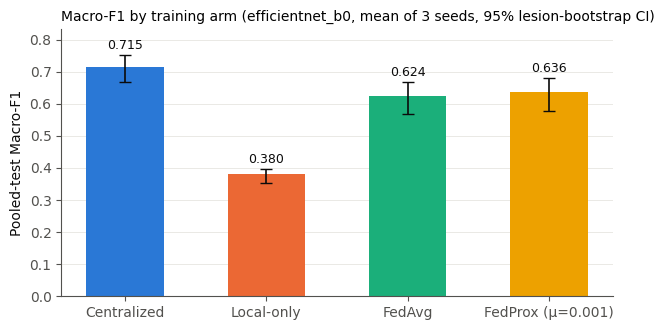

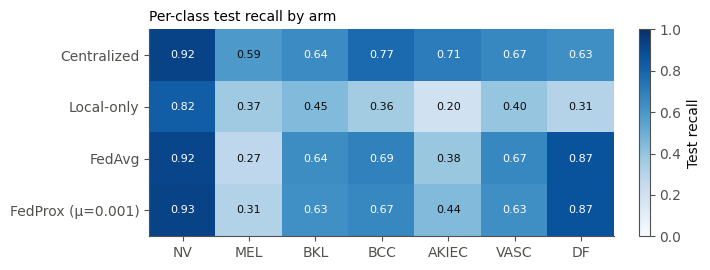

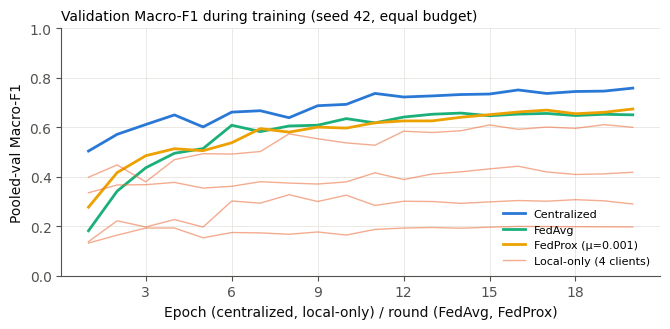

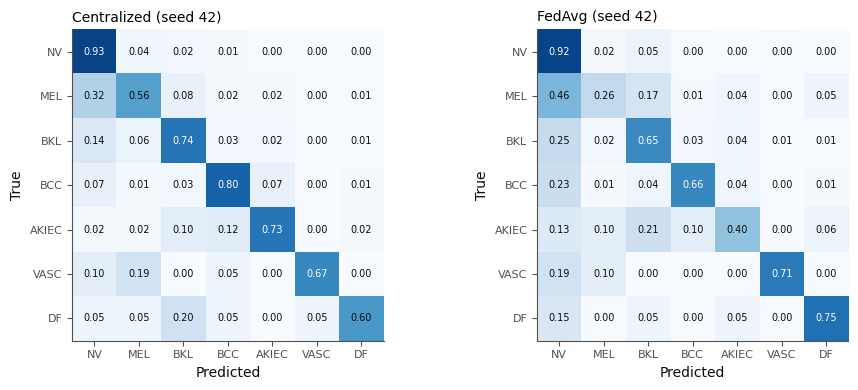

In [13]:
ARM_COLORS = dict(zip(ARMS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))  # validated categorical slots 1-4
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "font.size": 10, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})

# (1) Macro-F1 by arm with lesion-bootstrap CI ---------------------------------
fig, ax = plt.subplots(figsize=(6.4, 3.4))
y = summary["test_macro_f1"].to_numpy()
err = np.vstack([y - summary["ci_low"], summary["ci_high"] - y])
ax.bar(range(len(ARMS)), y, width=0.55, color=[ARM_COLORS[a] for a in ARMS], zorder=2)
ax.errorbar(range(len(ARMS)), y, yerr=err, fmt="none", ecolor=INK, elinewidth=1.2, capsize=4, zorder=3)
for i, v in enumerate(y):
    ax.text(i, summary["ci_high"].iloc[i] + 0.01, f"{v:.3f}", ha="center", va="bottom", color=INK, fontsize=9)
ax.set_xticks(range(len(ARMS)), ARMS)
ax.set_ylabel("Pooled-test Macro-F1")
ax.set_ylim(0, min(1, summary["ci_high"].max() + 0.08))
ax.grid(axis="x", visible=False)
ax.set_title(f"Macro-F1 by training arm ({PRIMARY}, mean of {len(SEEDS)} seeds, 95% lesion-bootstrap CI)",
             fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig_macro_f1_by_arm.png", dpi=300); plt.show()

# (2) Per-class recall heatmap -------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 2.8))
im = ax.imshow(recall.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(CLASSES)), [c.upper() for c in CLASSES]); ax.set_yticks(range(len(ARMS)), ARMS)
ax.grid(False)
for i in range(len(ARMS)):
    for j in range(len(CLASSES)):
        v = recall.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
fig.colorbar(im, ax=ax, label="Test recall", fraction=0.025)
ax.set_title("Per-class test recall by arm", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig_per_class_recall.png", dpi=300); plt.show()

# (3) Validation curves, seed 42 ----------------------------------------------
fig, ax = plt.subplots(figsize=(6.8, 3.4))
curves = {"Centralized": f"centralized_{PRIMARY}_s42", "FedAvg": f"fedavg_{PRIMARY}_s42",
          ARMS[3]: f"fedprox-mu{MU_BEST:g}_{PRIMARY}_s42"}
for a, n in curves.items():
    h = pd.read_csv(RUNS_DIR / n / "history.csv")
    ax.plot(h["step"], h["val_macro_f1"], color=ARM_COLORS[a], lw=2, label=a)
for i, c in enumerate(CLIENTS):
    h = pd.read_csv(RUNS_DIR / f"local-{c}_{PRIMARY}_s42" / "history.csv")
    ax.plot(h["step"], h["val_macro_f1"], color=ARM_COLORS["Local-only"], lw=1, alpha=0.55,
            label="Local-only (4 clients)" if i == 0 else None)
ax.set_xlabel("Epoch (centralized, local-only) / round (FedAvg, FedProx)")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylabel("Pooled-val Macro-F1"); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Validation Macro-F1 during training (seed 42, equal budget)", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig_val_curves.png", dpi=300); plt.show()

# (4) Row-normalized confusion matrices, seed 42 ---------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0))
for ax, (a, n) in zip(axes, [("Centralized", f"centralized_{PRIMARY}_s42"), ("FedAvg", f"fedavg_{PRIMARY}_s42")]):
    cm = np.array(metrics(n)["test"]["confusion_matrix"], dtype=float)
    cmn = np.divide(cm, cm.sum(1, keepdims=True), out=np.zeros_like(cm), where=cm.sum(1, keepdims=True) > 0)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.6 else INK)
    ax.set_xticks(range(len(CLASSES)), [c.upper() for c in CLASSES], fontsize=8)
    ax.set_yticks(range(len(CLASSES)), [c.upper() for c in CLASSES], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{a} (seed 42)", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig_confusion_central_vs_fedavg.png", dpi=300); plt.show()

## 11. LaTeX table for the IEEE report

In [14]:
def pm(m, sd):
    return f"{m:.3f}" if np.isnan(sd) else f"{m:.3f} $\\pm$ {sd:.3f}"

lines = []
for a in ARMS:
    r = summary.loc[a]
    ci = f"[{r.ci_low:.3f}, {r.ci_high:.3f}]"
    gap = "--" if a == "Centralized" else f"{r.gap_vs_central:+.3f} [{r.gap_ci_low:+.3f}, {r.gap_ci_high:+.3f}]"
    label = a.replace("µ", "$\\mu$")
    lines.append(f"{label} & {pm(r.test_macro_f1, r.test_macro_f1_sd)} & {ci} & {gap} & "
                 f"{r.test_bal_acc:.3f} & {r.test_acc:.3f} \\\\")
latex = "\n".join([
    "\\begin{table}[t]",
    f"\\caption{{Pooled-test results ({PRIMARY}, {len(SEEDS)} seeds, equal training budget). "
    "CIs: 95\\% bootstrap over test lesions.}",
    "\\label{tab:main_results}", "\\centering", "\\footnotesize", "\\setlength{\\tabcolsep}{3pt}",
    "\\begin{tabular}{lccccc}", "\\hline",
    "Arm & Macro-F1 & 95\\% CI & Gap vs. central. & Bal. acc. & Acc. \\\\", "\\hline",
    *lines, "\\hline", "\\end{tabular}", "\\end{table}"])
(RESULTS_DIR / "table_main_results.tex").write_text(latex + "\n", encoding="utf-8")
print(latex)

\begin{table}[t]
\caption{Pooled-test results (efficientnet_b0, 3 seeds, equal training budget). CIs: 95\% bootstrap over test lesions.}
\label{tab:main_results}
\centering
\footnotesize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{lccccc}
\hline
Arm & Macro-F1 & 95\% CI & Gap vs. central. & Bal. acc. & Acc. \\
\hline
Centralized & 0.715 $\pm$ 0.012 & [0.669, 0.752] & -- & 0.706 & 0.834 \\
Local-only & 0.380 $\pm$ 0.005 & [0.353, 0.396] & -0.336 [-0.368, -0.302] & 0.414 & 0.673 \\
FedAvg & 0.624 $\pm$ 0.006 & [0.569, 0.668] & -0.091 [-0.129, -0.050] & 0.634 & 0.781 \\
FedProx ($\mu$=0.001) & 0.636 $\pm$ 0.021 & [0.577, 0.680] & -0.080 [-0.120, -0.038] & 0.640 & 0.791 \\
\hline
\end{tabular}
\end{table}


## 12. Export models for the Gradio demo + download bundle

The demo shows the federated model next to the centralized model (proposal Sec. VI). Preprocessing in the demo must match training: RGB → resize to 224×224 (bilinear, no crop) → ImageNet mean/std.

In [15]:
FULL_NAMES = {"nv": "Melanocytic nevus", "mel": "Melanoma", "bkl": "Benign keratosis-like lesion",
              "bcc": "Basal cell carcinoma", "akiec": "Actinic keratosis / intraepithelial carcinoma",
              "vasc": "Vascular lesion", "df": "Dermatofibroma"}
export = {"centralized": f"centralized_{PRIMARY}_s42", "fedavg": f"fedavg_{PRIMARY}_s42",
          "fedprox": f"fedprox-mu{MU_BEST:g}_{PRIMARY}_s42"}
card = {"backbone": PRIMARY, "classes": CLASSES, "class_names": FULL_NAMES, "img_size": 224,
        "resize": "PIL bilinear to 224x224, no crop", "mean": list(fl_train.IMAGENET_MEAN),
        "std": list(fl_train.IMAGENET_STD), "fedprox_mu": MU_BEST, "models": {}}
for key, name in export.items():
    shutil.copy(RUNS_DIR / name / "best.pt", DEMO_DIR / f"{key}_{PRIMARY}.pt")
    m = metrics(name)
    card["models"][key] = {"file": f"{key}_{PRIMARY}.pt", "run": name,
                           "test_macro_f1": round(m["test"]["macro_f1"], 4),
                           "test_bal_acc": round(m["test"]["balanced_accuracy"], 4)}
(DEMO_DIR / "model_card.json").write_text(json.dumps(card, indent=2))

# Bundle: results + demo models + per-run metrics/history/preds/logs (not every checkpoint)
bundle = WORK / "bundle"
shutil.rmtree(bundle, ignore_errors=True)
shutil.copytree(RESULTS_DIR, bundle / "results")
shutil.copytree(DEMO_DIR, bundle / "demo_models")
shutil.copytree(LOG_DIR, bundle / "logs")
shutil.copy("fl_train.py", bundle / "fl_train.py")
for d in RUNS_DIR.iterdir():
    if (d / "metrics.json").exists():
        (bundle / "runs" / d.name).mkdir(parents=True)
        for f in ("metrics.json", "history.csv", "preds.npz"):
            shutil.copy(d / f, bundle / "runs" / d.name / f)
archive = shutil.make_archive(str(WORK / "ham10000_fl_results"), "zip", bundle)
shutil.rmtree(bundle)
print(f"Download: {archive} ({Path(archive).stat().st_size / 1e6:.0f} MB)")
print(json.dumps(card["models"], indent=2))

Download: /kaggle/working/ham10000_fl_results.zip (48 MB)
{
  "centralized": {
    "file": "centralized_efficientnet_b0.pt",
    "run": "centralized_efficientnet_b0_s42",
    "test_macro_f1": 0.7288,
    "test_bal_acc": 0.7179
  },
  "fedavg": {
    "file": "fedavg_efficientnet_b0.pt",
    "run": "fedavg_efficientnet_b0_s42",
    "test_macro_f1": 0.6202,
    "test_bal_acc": 0.6237
  },
  "fedprox": {
    "file": "fedprox_efficientnet_b0.pt",
    "run": "fedprox-mu0.001_efficientnet_b0_s42",
    "test_macro_f1": 0.6599,
    "test_bal_acc": 0.6633
  }
}


## 13. Notes for the report (fill from the outputs above)

- **Deviation from proposal Sec. IV-E:** training hyperparameters were fixed a priori (listed at the top) instead of tuned on centralized validation, because of time. They are identical for all arms, so the comparison stays fair.
- **Hardware:** Kaggle 2× NVIDIA T4 (one run per GPU), not the RTX 5070 named in the proposal; the GPU is recorded in every `metrics.json` (`env.gpu`). Mixed precision (fp16) and `cudnn.benchmark` are used, so reruns can differ slightly in the last digits.
- **Class weights** come from the pooled training class counts. In a real federation this needs clients to share their label counts; state this under limitations.
- **FedAvg aggregates BatchNorm running statistics** together with the weights (plain FedAvg). FedBN (FL-006) was not run.
- Report `backbone_decision.json`, `fedprox_mu_selection.csv`, `main_results.csv`, `per_class_gap.csv` and the four figures.